# Лабораторная работа №2. Свёрточные нейронные сети

**Вариант 19:** архитектура **VGG**, ядра для п. 3: $k_1 = 15$, $k_2 = 75$, $k_3 = 3$.

**Датасет:** CIFAR-10 — цветные картинки 32×32, 10 классов. 50 000 картинок для обучения

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Данные

In [2]:
transform = T.ToTensor()
transform_aug = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor()])

train_set = torchvision.datasets.CIFAR10("data", train=True, download=True, transform=transform)
train_set_aug = torchvision.datasets.CIFAR10("data", train=True, download=True, transform=transform_aug)
test_set = torchvision.datasets.CIFAR10("data", train=False, download=True, transform=transform)
classes = test_set.classes

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
train_loader_aug = DataLoader(train_set_aug, batch_size=128, shuffle=True)
test_loader = DataLoader(test_set, batch_size=512)

print("train:", len(train_set), " test:", len(test_set))
print("классы:", classes)

train: 50000  test: 10000
классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 0. Собственная CNN

Три блока **свёртка 3×3 → ReLU → MaxPool 2×2**, затем полносвязный слой на 10 классов.
Свёртка с `padding=1` не меняет размер картинки, MaxPool 2×2 уменьшает его вдвое: 32 → 16 → 8 → 4.

In [ ]:
class MyCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 3×32×32 -> 64×16×16
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # -> 128×8×8
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # -> 256×4×4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),               # 256×4×4 -> вектор длины 4096
            nn.Dropout(dropout),
            nn.Linear(4096, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters())


print(MyCNN())
print("Параметров:", count_params(MyCNN()))

MyCNN(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.0, inplace=False)
    (2): Linear(in_features=4096, out_features=10, bias=True)
  )
)
Параметров: 411786


## 1.VGG

Отличия от оригинала (он сделан для картинок 224×224 и 1000 классов):
* после каждой свёртки добавлен BatchNorm (нормализация выхода слоя) — без него VGG-16 с нуля почти не обучается;
* картинка 32×32 после 5 MaxPool становится 1×1 с 512 каналами, поэтому полносвязные слои 512 → 512 → 512 → 10
  (в оригинале 25088 → 4096 → 4096 → 1000).

In [4]:
VGG16 = [64, 64, "M", 128, 128, "M", 256, 256, 256, "M", 512, 512, 512, "M", 512, 512, 512, "M"]


class VGG(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        in_channels = 3
        for v in VGG16:
            if v == "M":
                layers.append(nn.MaxPool2d(2))
            else:
                layers += [nn.Conv2d(in_channels, v, kernel_size=3, padding=1), nn.BatchNorm2d(v), nn.ReLU()]
                in_channels = v
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


print(VGG())
print("Параметров:", count_params(VGG()))

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1,

## 2. Обучение

Функция потерь — CrossEntropy, оптимизатор — Adam. После каждой эпохи считаем loss и accuracy
на train и на test.

In [ ]:
loss_fn = nn.CrossEntropyLoss()


def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss = loss_fn(out, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += loss_fn(out, y).item() * len(y) #из-за последнего батча
        correct += (out.argmax(1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)


def train(model, loader, epochs):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_epoch(model, loader, optimizer)
        test_loss, test_acc = evaluate(model, test_loader)
        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        print(f"эпоха {epoch:2d}: train loss {train_loss:.3f}, acc {train_acc:.3f} | "
              f"test loss {test_loss:.3f}, acc {test_acc:.3f}")
    return history


def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
    ax1.plot(epochs, history["train_loss"], label="train")
    ax1.plot(epochs, history["test_loss"], label="test")
    ax1.set_title(f"{title}: loss")
    ax2.plot(epochs, history["train_acc"], label="train")
    ax2.plot(epochs, history["test_acc"], label="test")
    ax2.set_title(f"{title}: accuracy")
    for ax in (ax1, ax2):
        ax.set_xlabel("эпоха")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.show()

### Борьба с переобучением

Сначала обучаем `MyCNN` без защиты от переобучения:

эпоха  1: train loss 1.483, acc 0.464 | test loss 1.183, acc 0.573


эпоха  2: train loss 1.056, acc 0.628 | test loss 1.023, acc 0.644


эпоха  3: train loss 0.880, acc 0.695 | test loss 0.879, acc 0.693


эпоха  4: train loss 0.763, acc 0.736 | test loss 0.815, acc 0.721


эпоха  5: train loss 0.674, acc 0.767 | test loss 0.800, acc 0.726


эпоха  6: train loss 0.604, acc 0.792 | test loss 0.756, acc 0.744


... (10 outputs left out)

эпоха 17: train loss 0.114, acc 0.961 | test loss 1.151, acc 0.747


эпоха 18: train loss 0.100, acc 0.966 | test loss 1.204, acc 0.749


эпоха 19: train loss 0.095, acc 0.968 | test loss 1.257, acc 0.744


эпоха 20: train loss 0.082, acc 0.972 | test loss 1.374, acc 0.738


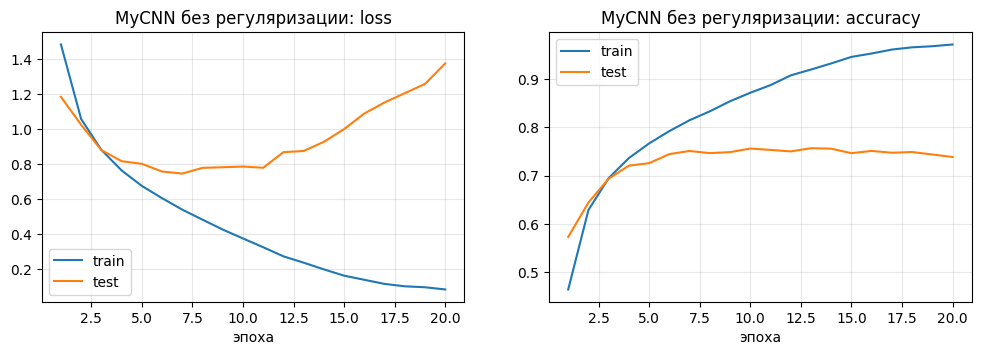

In [6]:
my_cnn_plain = MyCNN(dropout=0.0)
history_plain = train(my_cnn_plain, train_loader, epochs=20)
plot_history(history_plain, "MyCNN без регуляризации")

**Видно переобучение:** точность на train дошла до 97,2 %, а на test остановилась около 75 %

**Борьба с переобучением:** обучаем ту же сеть с аугментацией (`train_loader_aug`) и Dropout 0.5.

эпоха  1: train loss 1.697, acc 0.378 | test loss 1.348, acc 0.517


эпоха  2: train loss 1.386, acc 0.499 | test loss 1.197, acc 0.571


эпоха  3: train loss 1.241, acc 0.553 | test loss 1.082, acc 0.609


эпоха  4: train loss 1.139, acc 0.595 | test loss 0.965, acc 0.664


эпоха  5: train loss 1.067, acc 0.623 | test loss 0.901, acc 0.681


эпоха  6: train loss 1.001, acc 0.647 | test loss 0.869, acc 0.695


... (10 outputs left out)

эпоха 17: train loss 0.734, acc 0.743 | test loss 0.658, acc 0.778


эпоха 18: train loss 0.716, acc 0.752 | test loss 0.634, acc 0.785


эпоха 19: train loss 0.703, acc 0.755 | test loss 0.633, acc 0.781


эпоха 20: train loss 0.698, acc 0.756 | test loss 0.641, acc 0.779


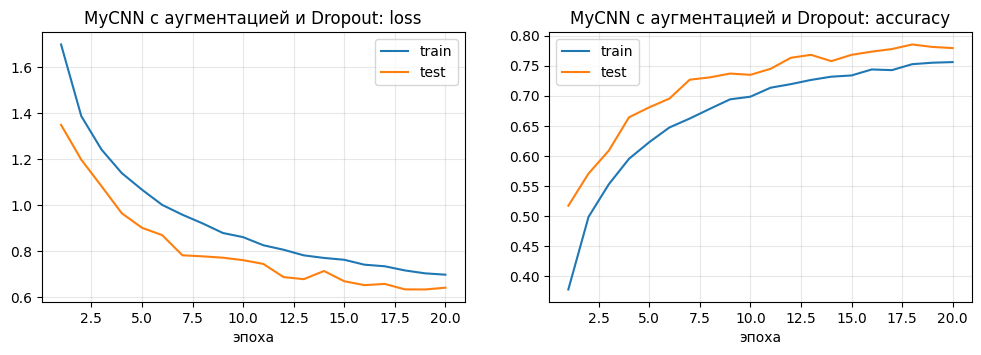

In [7]:
my_cnn = MyCNN(dropout=0.5)
history_my = train(my_cnn, train_loader_aug, epochs=20)
plot_history(history_my, "MyCNN с аугментацией и Dropout")

**Переобучение устранено:** test loss больше не растёт, точность на test выросла с 73,8 до 77,9 %.
Точность на train (75,6 %) теперь даже ниже, чем на test: при обучении включены аугментация и Dropout,
поэтому на train задача сложнее, чем на test.

### Обучение VGG-16

Используем те же меры против переобучения: аугментация и Dropout.

эпоха  1: train loss 1.916, acc 0.208 | test loss 1.790, acc 0.287


эпоха  2: train loss 1.595, acc 0.354 | test loss 1.720, acc 0.347


эпоха  3: train loss 1.411, acc 0.447 | test loss 1.227, acc 0.541


эпоха  4: train loss 1.174, acc 0.581 | test loss 1.059, acc 0.631


эпоха  5: train loss 1.008, acc 0.651 | test loss 1.131, acc 0.605


эпоха  6: train loss 0.891, acc 0.700 | test loss 1.001, acc 0.670


... (10 outputs left out)

эпоха 17: train loss 0.420, acc 0.869 | test loss 0.486, acc 0.851


эпоха 18: train loss 0.396, acc 0.876 | test loss 0.574, acc 0.821


эпоха 19: train loss 0.386, acc 0.880 | test loss 0.468, acc 0.851


эпоха 20: train loss 0.368, acc 0.884 | test loss 0.424, acc 0.865


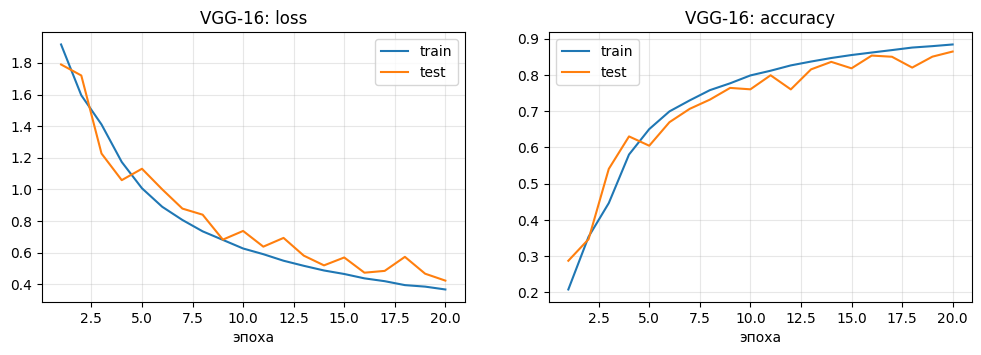

In [8]:
vgg = VGG()
history_vgg = train(vgg, train_loader_aug, epochs=20)
plot_history(history_vgg, "VGG-16")

VGG-16 на 20-й эпохе: train 88,4 %, test 86,5 %. Разрыв маленький, test loss не растёт — переобучения нет.
Точность выше, чем у MyCNN, и на train, и на test, но пойдет

## 2.1. Валидация модели классификации

Проверяем обученные модели на test (10 000 картинок, на которых модели не обучались):
* **accuracy** — доля правильных ответов;
* **precision** класса — из картинок, которые модель отнесла к этому классу, доля правильных;
* **recall** класса — из всех картинок этого класса доля найденных моделью;
* **F1** — среднее гармоническое precision и recall;
* **матрица ошибок** — строка = настоящий класс, столбец = ответ модели.

MyCNN:  accuracy = 0.779
VGG-16: accuracy = 0.865

              precision    recall  f1-score   support

    airplane      0.878     0.875     0.876      1000
  automobile      0.885     0.966     0.924      1000
        bird      0.809     0.831     0.820      1000
         cat      0.735     0.700     0.717      1000
        deer      0.875     0.861     0.868      1000
         dog      0.823     0.760     0.790      1000
        frog      0.881     0.915     0.897      1000
       horse      0.896     0.908     0.902      1000
        ship      0.924     0.926     0.925      1000
       truck      0.934     0.907     0.920      1000

    accuracy                          0.865     10000
   macro avg      0.864     0.865     0.864     10000
weighted avg      0.864     0.865     0.864     10000



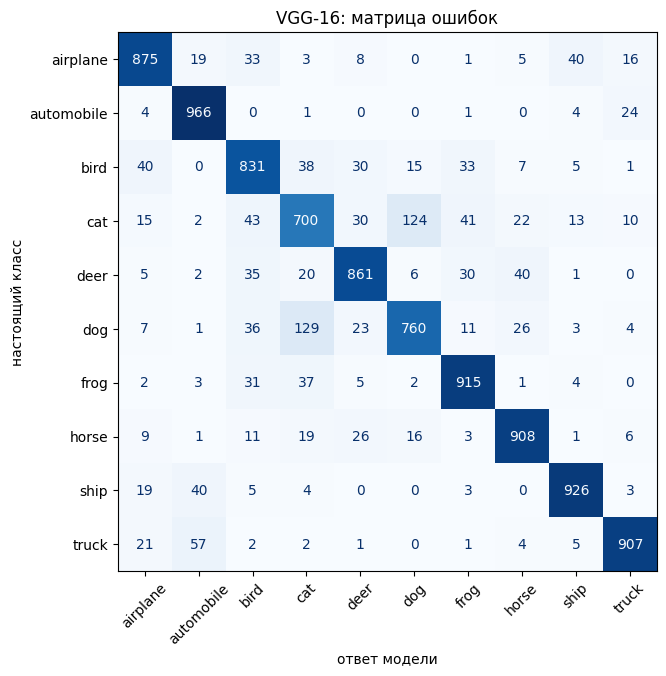

In [9]:
@torch.no_grad()
def predict(model):
    model.eval()
    preds, labels = [], []
    for x, y in test_loader:
        preds.append(model(x.to(device)).argmax(1).cpu())
        labels.append(y)
    return torch.cat(preds), torch.cat(labels)


my_pred, y_true = predict(my_cnn)
vgg_pred, _ = predict(vgg)
print(f"MyCNN:  accuracy = {(my_pred == y_true).float().mean():.3f}")
print(f"VGG-16: accuracy = {(vgg_pred == y_true).float().mean():.3f}")
print()
print(classification_report(y_true, vgg_pred, target_names=classes, digits=3))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_true, vgg_pred, display_labels=classes,
                                        xticks_rotation=45, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("VGG-16: матрица ошибок")
ax.set_xlabel("ответ модели")
ax.set_ylabel("настоящий класс")
plt.show()

VGG-16 — **86,5 %** на test, MyCNN — **77,9 %**.
Лучше всего VGG-16 распознаёт ship, automobile и truck (F1 ≈ 0,92), хуже всего — cat (0,72) и dog (0,79):
по матрице ошибок 124 кошки названы собаками и 129 собак — кошками.

## 3. Замена большой свёртки свёртками меньшего размера

Стек из $n$ свёрток $s \times s$ имеет рецептивное поле $1 + n\,(s - 1)$:
каждый следующий слой расширяет его на $s - 1$ пиксель.
Чтобы поле было как у одной свёртки $k \times k$, нужно $n = \dfrac{k - 1}{s - 1}$ слоёв.

| Ядро | Чем заменяем | Слоёв $n$ |
|---|---|---|
| 15×15 | 3×3 | (15 − 1) / 2 = 7 |
| 75×75 | 3×3 | (75 − 1) / 2 = 37 |
| 3×3 | 2×2 | (3 − 1) / 1 = 2 |

Считаем для слоя с $C = 64$ входными и выходными каналами на карте 64×64 (без bias):
* параметры: у свёртки $k \times k$ их $k^2 C^2$, у стека $n\, s^2 C^2$;
* операции (умножения): каждый вес умножается один раз на каждый пиксель выхода,
  поэтому операций = параметры × 64 × 64.

In [10]:
C, H, W = 64, 64, 64

for k, s in [(15, 3), (75, 3), (3, 2)]:
    n = (k - 1) // (s - 1)
    big = nn.Conv2d(C, C, kernel_size=k, bias=False)
    stack = nn.Sequential(*[nn.Conv2d(C, C, kernel_size=s, bias=False) for _ in range(n)])

    params_big, params_stack = count_params(big), count_params(stack)
    ops_big, ops_stack = params_big * H * W, params_stack * H * W

    print(f"Свёртка {k}×{k} -> стек из {n} свёрток {s}×{s}")
    print(f"  параметров: {params_big} -> {params_stack} (меньше в {params_big / params_stack:.2f} раза)")
    print(f"  умножений:  {ops_big / 1e6:.0f} млн -> {ops_stack / 1e6:.0f} млн")
    print(f"  слоёв:      1 -> {n}")

Свёртка 15×15 -> стек из 7 свёрток 3×3
  параметров: 921600 -> 258048 (меньше в 3.57 раза)
  умножений:  3775 млн -> 1057 млн
  слоёв:      1 -> 7
Свёртка 75×75 -> стек из 37 свёрток 3×3
  параметров: 23040000 -> 1363968 (меньше в 16.89 раза)
  умножений:  94372 млн -> 5587 млн
  слоёв:      1 -> 37
Свёртка 3×3 -> стек из 2 свёрток 2×2
  параметров: 36864 -> 32768 (меньше в 1.12 раза)
  умножений:  151 млн -> 134 млн
  слоёв:      1 -> 2


**Вывод.** Параметров становится меньше: в 3,57 раза для 15×15, в 16,9 раза для 75×75 и в 1,125 раза для 3×3.
Умножений становится меньше во столько же раз. Зато растёт количество последовательных операций:
вместо одного слоя — 7, 37 и 2 слоя, которые выполняются друг за другом (каждый ждёт результат предыдущего),
и каждый хранит в памяти свою карту признаков.

## 4. Эквивариантность свёртки

Свёртка **эквивариантна к сдвигу**: сдвинуть картинку и потом применить свёртку — то же самое,
что применить свёртку и потом сдвинуть результат.

**Доказательство.** Свёртка картинки $x$ с ядром $w$:
$$(x * w)[i, j] = \sum_{u, v} x[i + u,\, j + v]\; w[u, v].$$
Сдвиг на $(a, b)$: $(T x)[i, j] = x[i - a,\, j - b]$. Подставляем сдвинутую картинку:
$$\big((T x) * w\big)[i, j] = \sum_{u, v} x[i - a + u,\, j - b + v]\; w[u, v] = (x * w)[i - a,\, j - b] = \big(T (x * w)\big)[i, j].$$
Получили $(T x) * w = T (x * w)$. ∎

Проверка в коде. Чтобы равенство было точным и на краях картинки, сдвиг циклический (`torch.roll`:
то, что ушло за правый край, появляется слева), и padding у свёртки тоже циклический (`padding_mode="circular"`).

In [11]:
conv = nn.Conv2d(3, 8, kernel_size=5, padding=2, padding_mode="circular", bias=False)
x = torch.randn(1, 3, 32, 32)


def shift(t):
    return torch.roll(t, shifts=(6, 10), dims=(2, 3))  # сдвиг на 6 пикселей вниз и на 10 вправо


with torch.no_grad():
    a = conv(shift(x))  # сначала сдвиг, потом свёртка
    b = shift(conv(x))  # сначала свёртка, потом сдвиг

print("conv(shift(x)) == shift(conv(x)):", torch.allclose(a, b))

conv(shift(x)) == shift(conv(x)): True


## 5. Оператор деконволюции

Деконволюция (транспонированная свёртка) **увеличивает** картинку — обратно обычной свёртке со stride.
В компьютерном зрении её используют, когда нужно восстановить размер: сегментация (U-Net), автоэнкодеры.

Как работает: каждый пиксель входа умножается на всё ядро $K \times K$, и результат прибавляется к выходу
в позицию (строка × stride, столбец × stride). Там, где такие квадраты перекрываются, значения складываются.
Размер выхода: $O = (I - 1) \cdot S + K$.

In [12]:
def deconv2d(x, kernel, stride=1):
    """x — вход H×W, kernel — ядро K×K."""
    H, W = x.shape
    K = kernel.shape[0]
    out = torch.zeros((H - 1) * stride + K, (W - 1) * stride + K)
    for i in range(H):
        for j in range(W):
            out[i * stride:i * stride + K, j * stride:j * stride + K] += x[i, j] * kernel
    return out


x = torch.tensor([[1., 2.],
                  [3., 4.]])
kernel = torch.tensor([[1., 2., 3.],
                       [4., 5., 6.],
                       [7., 8., 9.]])

mine = deconv2d(x, kernel, stride=2)
# в PyTorch вход и ядро должны быть 4-мерными (батч, каналы, высота, ширина), поэтому view(1, 1, ...)
torch_result = F.conv_transpose2d(x.view(1, 1, 2, 2), kernel.view(1, 1, 3, 3), stride=2).view(5, 5)

print("Наша функция:\n", mine)
print("PyTorch:\n", torch_result)
print("Совпадает:", torch.equal(mine, torch_result))

Наша функция:
 tensor([[ 1.,  2.,  5.,  4.,  6.],
        [ 4.,  5., 14., 10., 12.],
        [10., 14., 36., 24., 30.],
        [12., 15., 34., 20., 24.],
        [21., 24., 55., 32., 36.]])
PyTorch:
 tensor([[ 1.,  2.,  5.,  4.,  6.],
        [ 4.,  5., 14., 10., 12.],
        [10., 14., 36., 24., 30.],
        [12., 15., 34., 20., 24.],
        [21., 24., 55., 32., 36.]])
Совпадает: True


## 6. Формула размера карты признаков после свёртки

$$O = \left\lfloor \frac{I - K + 2P}{S} \right\rfloor + 1$$

$I$ — размер входа, $K$ — размер ядра, $P$ — padding (сколько пикселей добавляем с каждой стороны),
$S$ — stride (шаг ядра), $O$ — размер выхода.

**Объяснение.**
1. После padding размер входа равен $I + 2P$.
2. Ядро ставится в позиции $0, S, 2S, \dots$ Оно должно целиком помещаться во вход,
   поэтому последняя возможная позиция — $I + 2P - K$.
3. Число шагов длины $S$ от 0 до $I + 2P - K$ равно $\left\lfloor \frac{I + 2P - K}{S} \right\rfloor$
   (округление вниз: неполный шаг не делается).
4. $+1$ — начальная позиция 0. Каждая позиция ядра даёт один пиксель выхода.

**Пример:** $I = 7,\ K = 3,\ P = 0,\ S = 2$. Ядро встаёт в позиции 0, 2, 4 (в позицию 6 уже не помещается),
$O = \lfloor (7 - 3)/2 \rfloor + 1 = 3$.

**В VGG:** свёртка $K = 3,\ P = 1,\ S = 1$ даёт $O = I$ (размер не меняется),
MaxPool $K = 2,\ P = 0,\ S = 2$ даёт $O = I / 2$ (для пулинга формула та же).

In [13]:
def conv_out_size(I, K, P, S):
    return (I - K + 2 * P) // S + 1


for I, K, P, S in [(32, 3, 1, 1), (32, 2, 0, 2), (7, 3, 0, 2), (8, 3, 0, 2)]:
    real = nn.Conv2d(1, 1, kernel_size=K, stride=S, padding=P)(torch.zeros(1, 1, I, I)).shape[-1]
    print(f"I={I}, K={K}, P={P}, S={S}: по формуле {conv_out_size(I, K, P, S)}, в PyTorch {real}")

I=32, K=3, P=1, S=1: по формуле 32, в PyTorch 32
I=32, K=2, P=0, S=2: по формуле 16, в PyTorch 16
I=7, K=3, P=0, S=2: по формуле 3, в PyTorch 3
I=8, K=3, P=0, S=2: по формуле 3, в PyTorch 3


## Выводы

0. Собственная CNN (3 свёрточных блока, 0,41 млн параметров) — 77,9 % на test.
1. VGG-16 (15,3 млн параметров) — 86,5 % на test, fine-tuning не понадобился.
2. Без регуляризации MyCNN переобучается (train 97 %, test 74 %, test loss растёт).
   Аугментация и Dropout убрали переобучение и подняли точность на test до 77,9 %.
   Более ёмкая VGG-16 даёт более высокую точность и на train, и на test.
3. Замена свёртки стеком свёрток меньшего размера с тем же рецептивным полем уменьшает число параметров
   и умножений в 3,57 раза (15×15), в 16,9 раза (75×75) и в 1,125 раза (3×3), но число последовательных
   слоёв растёт до 7, 37 и 2.
4. Эквивариантность свёртки к сдвигу доказана и проверена в коде.
5. Своя функция деконволюции даёт тот же результат, что и `F.conv_transpose2d` в PyTorch.
6. Формула размера карты признаков объяснена и проверена на слоях PyTorch.